# Initialization and data loading

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision import transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

train_transforms = transforms.Compose([transforms.RandomHorizontalFlip(),
                                       transforms.ToTensor(), transforms.Normalize(0.5,0.5)])
test_transforms = transforms.Compose([transforms.ToTensor(), transforms.Normalize(0.5,0.5)])


train_dataset = datasets.MNIST('./data', train=True, download=True,
                               transform=train_transforms)

x_train, y_train = train_dataset.data, train_dataset.targets

test_dataset = datasets.MNIST('./data', train=False, download=True,
                              transform=test_transforms)

x_test, y_test = test_dataset.data, test_dataset.targets


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 10.7MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.6MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.87MB/s]


# Anomaly class selection


In [17]:
# TODO: choose a random class as anomalous and one as normal
n_classes = len(np.unique(y_train))
normal_class: int | None = None  # Must be set to an integere
anomalous_class: int | None = None  # Must be set to an integer

IndexError: index 0 is out of bounds for dimension 0 with size 0

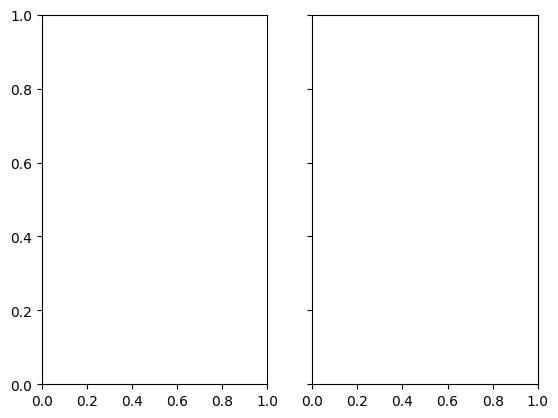

In [18]:
# print and log stuff
fig, ax = plt.subplots(nrows=1,ncols=2, sharey=True)
ax[0].imshow(x_train[y_train == normal_class][0], cmap='gray')
ax[0].set_title(f"Normal ({normal_class})")
ax[1].imshow(x_train[y_train == anomalous_class][0], cmap='gray')
ax[1].set_title(f"Anomaly (class {anomalous_class})")
plt.show()

 # update train targets
train_dataset.data = x_train[y_train == normal_class]
train_dataset.targets = y_train[y_train == normal_class]

 # update test targets
test_dataset.data = x_test[(y_test == anomalous_class) | (y_test == normal_class)]
test_dataset.targets = y_test[(y_test == anomalous_class) | (y_test == normal_class)]
test_dataset.targets = test_dataset.targets == anomalous_class

# Define the model

In [4]:
BATCH_SIZE      = 32                # number of data points in each batch
N_EPOCHS        = 10                 # times to run the model on complete data
INPUT_DIM       = 28 * 28           # size of each input
HIDDEN_DIM      = 256               # hidden dimension
LATENT_DIM      = 64                # latent vector dimension
lr              = 1e-2              # learning rate
noise_mean, noise_stddev = 0.0, 0.3 # parameters for denoising

In [5]:
class DeepDenoisingAutoencoder(nn.Module):

  def __init__(self):
    super(DeepDenoisingAutoencoder, self).__init__()


    # TODO: create autoencoder layers
    self.encoder = nn.Sequential()

    self.decoder = nn.Sequential()


  def forward(self, x: torch.Tensor):

    # TODO: compute the forward

    return x


# Model initialization

In [6]:
from torch.utils.data import DataLoader

trainloader = DataLoader(train_dataset, shuffle=True, batch_size=BATCH_SIZE, num_workers=2)
testloader = DataLoader(test_dataset, shuffle=False, batch_size=BATCH_SIZE, num_workers=2)

In [7]:
model = DeepDenoisingAutoencoder()

# TODO: create the optimizer
opt = None

# TODO: create the criterion to compute the loss
criterion = None

In [8]:
@torch.no_grad()
def apply_noise(x: torch.Tensor):
  # TODO: add random noise to the input
  noise = torch.zeros_like(x).to(x.device)
  return x + noise

# Metrics computation

In [9]:
from sklearn import metrics

def compute_metrics(labels, preds):
    return metrics.roc_auc_score(labels, preds)


# Evaluation code

In [10]:
from tqdm import tqdm

def eval(model, testloader):
  model.eval()
  # Evaluate the model and return labels and predictions scores
  all_preds, all_labels = [], []
  with torch.no_grad():
    for x, y in tqdm(testloader, desc="Evaluation"):
      # TODO: compute the forward pass
      x = None
      reconstructed = None

      # TODO: compute reconstruction error
      error = None


  return all_labels, all_preds

# Train

In [11]:
model = DeepDenoisingAutoencoder()
model = model.to(device)

for e in range(N_EPOCHS):
      running_loss = 0
      model.train()
      for i, (x, _) in enumerate(trainloader):
        # TODO : compute forward and backward pass

            # TODO: Forward
            x = None
            x_noise = None
            reconstructed = None

            # TODO: Backward

            # TODO: Running loss logging
            running_loss += 0

            if i % 100 == 99:
                print(f'Epoch: {e+1} , Iteration: {i+1}, Loss: {running_loss:.3f}')
                running_loss = 0.0

      all_labels, all_preds = eval(model, testloader)
      roc_auc = compute_metrics(all_labels, all_preds)
      print("Current ROC AUC: %.3f" % roc_auc)

Epoch: 1 , Iteration: 100, Loss: 0.000


Evaluation: 100%|██████████| 62/62 [00:00<00:00, 99.58it/s] 


ValueError: Found array with 0 sample(s) (shape=(0,)) while a minimum of 1 is required.

In [ ]:
import matplotlib.pyplot as plt

def show_reconstructions(model, dataloader, device, classes=(0, 1), num_examples=5):
    model.eval()
    shown = {c: 0 for c in classes}
    fig, axs = plt.subplots(len(classes), 2 * num_examples, figsize=(2 * num_examples, len(classes)*2))

    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(device), y.to(device)
            x_flat = x.view(x.shape[0], -1)
            x_flat = apply_noise(x_flat)
            x_recon = model(x_flat).view_as(x)

            for i in range(x.size(0)):
                label = y[i].item()
                if label in classes and shown[label] < num_examples:
                    col = shown[label]
                    row = classes.index(label)
                    axs[row, col * 2].imshow(x[i].squeeze().cpu().numpy(), cmap='gray')
                    axs[row, col * 2].axis('off')
                    axs[row, col * 2].set_title(f"Orig: {label}")

                    axs[row, col * 2 + 1].imshow(x_recon[i].squeeze().cpu().numpy(), cmap='gray')
                    axs[row, col * 2 + 1].axis('off')
                    axs[row, col * 2 + 1].set_title("Recon")

                    shown[label] += 1

            if all(shown[c] >= num_examples for c in classes):
                break

    plt.tight_layout()
    plt.show()

show_reconstructions(model, testloader, device)